# A new ría with openEO: Santoña, as a dry run

How to map a new estuary with MAREA: choose the box, size the download, estimate its cost in openEO credits, and run the chain from the Sentinel-2 cube to the maps. The example is the Marismas de Santoña (Cantabria), with a box that holds the whole marsh system and reaches the open sea, so that MAREA finds the real mouth.

The notebook runs as a dry run: with `RUN_DOWNLOAD = False` nothing is downloaded, no openEO job is started and no credit is spent. With an account on the Copernicus Data Space Ecosystem and `RUN_DOWNLOAD = True`, the same cells download the cube and make the maps. The full guide, with the rules for drawing the box and how to judge a run, is `guide/NEW_ESTUARY.md`.

In [1]:
RUN_DOWNLOAD = False                                # True starts one openEO batch job: it needs an account and spends credits

# ── Setup: run from the repository root, whichever folder the notebook was opened in ──
import os                                           # the working directory
import platform                                     # the Python version
import sys                                          # where the library and the helpers are imported from
import warnings                                     # the outputs show results, not the packages' warnings
from pathlib import Path

warnings.filterwarnings('ignore')
ROOT = Path.cwd() if (Path.cwd() / 'pyintertidal').is_dir() else Path.cwd().parent
os.chdir(ROOT)                                      # every path below is relative to the repository root
for p in (str(ROOT), str(ROOT / 'scripts')):        # the library, and the helpers in scripts/
    if p not in sys.path:
        sys.path.insert(0, p)

import numpy as np
import pandas as pd
import pyproj                                       # the box on the UTM grid of the cube

import pyintertidal as pit                          # the MAREA library of this repository
from pyintertidal import overpass                   # UTM zones and the acquisition times of the scenes

# ── Provenance: the branch and the versions (this notebook reads no data file) ──
print('branch CARTOGRASS26 · notebooks/03_new_ria_openeo.ipynb')
print(f'Python {platform.python_version()} · pyintertidal {pit.__version__} · numpy {np.__version__} · '
      f'pandas {pd.__version__} · pyproj {pyproj.__version__}')
print(f'RUN_DOWNLOAD = {RUN_DOWNLOAD}')

branch CARTOGRASS26 · notebooks/03_new_ria_openeo.ipynb
Python 3.13.3 · pyintertidal 0.1.0 · numpy 2.4.6 · pandas 2.3.3 · pyproj 3.7.2
RUN_DOWNLOAD = False


## 1 · The box

openEO downloads the box's bounding box on the 10 m grid of the Sentinel-2 tiles, in the box's UTM zone. The number of pixels follows from the cells of that grid that the box touches.

In [2]:
aoi = pit.AOI.from_bbox(-3.56, 43.36, -3.40, 43.47, name='santona')   # west, south, east, north (degrees)
lat_c, lon_c = aoi.centroid                                 # the tide point of the chain below (better: open water off the mouth)
zone = overpass.utm_zone(lon_c)                             # the box's UTM zone
crs = f'EPSG:{32600 + zone}'                                # WGS 84 / UTM zone 30N
to_utm = pyproj.Transformer.from_crs('EPSG:4326', crs, always_xy=True)


def frame(box, step=10.0, n=200):
    # rows and columns of the 10 m grid over a box: the cells of the UTM lattice that its outline touches
    b = box.bbox
    lon = np.r_[np.linspace(b['west'], b['east'], n), np.full(n, b['east']),
                np.linspace(b['east'], b['west'], n), np.full(n, b['west'])]
    lat = np.r_[np.full(n, b['south']), np.linspace(b['south'], b['north'], n),
                np.full(n, b['north']), np.linspace(b['north'], b['south'], n)]
    x, y = to_utm.transform(lon, lat)
    rows = int(np.floor(y.max() / step) - np.floor(y.min() / step)) + 1
    cols = int(np.floor(x.max() / step) - np.floor(x.min() / step)) + 1
    return rows, cols


# the rule gives the frame of the authors' existing Santoña cubes (2023-2025), which used a narrower box
narrow = pit.AOI.from_bbox(-3.50, 43.40, -3.42, 43.46, name='santona_narrow')
assert frame(narrow) == (671, 652)
rows, cols = frame(aoi)
mpx = rows * cols / 1e6                                     # megapixels of 10 m (1 Mpx = 100 km2)
print(f'box: {aoi.area_km2:.0f} km2 around {lat_c:.3f} N {-lon_c:.3f} W (UTM zone {zone}, {crs})')
print(f'frame: {rows:,} x {cols:,} pixels of 10 m = {mpx:.2f} Mpx; the narrower box: 671 x 652 = '
      f'{671 * 652 / 1e6:.2f} Mpx')

box: 158 km2 around 43.415 N 3.480 W (UTM zone 30, EPSG:32630)
frame: 1,230 x 1,303 pixels of 10 m = 1.60 Mpx; the narrower box: 671 x 652 = 0.44 Mpx


## 1b · Check the box, offline

Five rules decide what MAREA can read inside a box (`guide/NEW_ESTUARY.md`, section 2): reach the open sea, keep the head of tide inside, one exit to the sea, one estuary per box, and enough flat (at least 3,000 intertidal pixels, and more than 5,000 with a water path to the mouth for a delay). Once a cube is on disk, its masks show where MAREA will put the mouth and how far the flats lie from it. The check below runs on the masks of the Villaviciosa replication kit, which needs no download; for Santoña the masks would come from `marea.extract(CUBE)` after the download.

32,120 intertidal pixels (MAREA stops below 3,000)
30,781 of them reach the mouth through water (a delay needs more than 5,000)
the farthest is 9.15 km from the mouth: 3 sections, centred at 1.49, 4.27, 7.57 km
permanent-sea pixels on each edge: {'north': 391, 'south': 0, 'west': 0, 'east': 199}


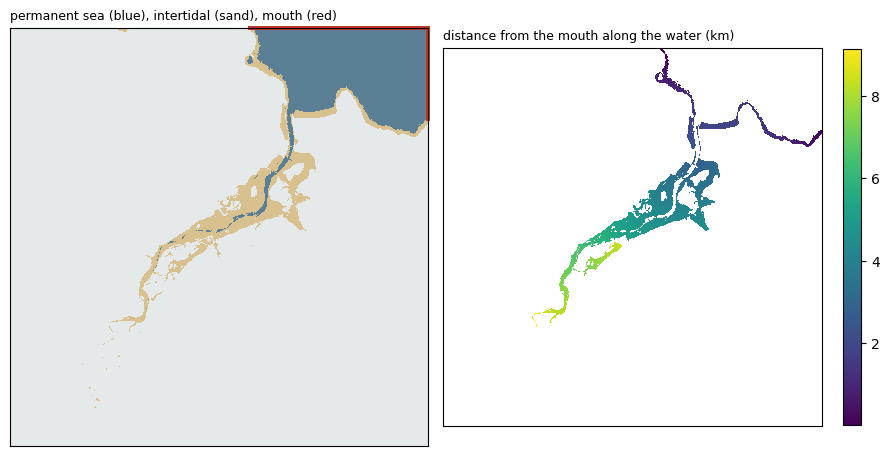

In [3]:
from matplotlib.colors import ListedColormap
import matplotlib.pyplot as plt

from pyintertidal import geometry, tide_estimators

kit = np.load('replication/villaviciosa_record_2023-2025.npz')   # Villaviciosa: the masks of step 4
sea, inter = kit['sea'], kit['inter']               # for a new cube: ex = marea.extract(CUBE), then ex['sea'], ex['inter']
seeds = geometry.mouth_seeds(sea, side='any')       # the mouth: permanent sea on the frame's edge
s_km = geometry.along_distance(sea | inter, seeds, 10.0) / 1000.0   # distance from the mouth through water
s_inter = s_km[inter]                               # the intertidal pixels, row by row
with np.errstate(invalid='ignore'):                 # pixels without a water path have no distance
    edges, centres, band = tide_estimators.make_bands_fixed(s_inter, 3.0, 500)
print(f'{inter.sum():,} intertidal pixels (MAREA stops below 3,000)')
print(f'{np.isfinite(s_inter).sum():,} of them reach the mouth through water (a delay needs more than 5,000)')
where = ', '.join(f'{x:.2f}' for x in centres)
print(f'the farthest is {np.nanmax(s_inter):.2f} km from the mouth: {len(centres)} sections, centred at {where} km')
print('permanent-sea pixels on each edge:', {'north': int(sea[0].sum()), 'south': int(sea[-1].sum()),
                                            'west': int(sea[:, 0].sum()), 'east': int(sea[:, -1].sum())})

fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 4.6))
classes = sea * 1 + inter * 2                       # 0 land, 1 permanent sea, 2 intertidal
a1.imshow(classes, cmap=ListedColormap(['#E6E9EA', '#5B7F95', '#D9C08F']), vmin=0, vmax=2, interpolation='nearest')
sr, sc = np.nonzero(seeds)
a1.scatter(sc, sr, s=12, color='#C0392B', marker='s', linewidths=0, clip_on=False)   # the mouth, on the edge
a1.set_title('permanent sea (blue), intertidal (sand), mouth (red)', loc='left', fontsize=9)
im = a2.imshow(np.where(inter, s_km, np.nan), cmap='viridis', interpolation='nearest')
a2.set_title('distance from the mouth along the water (km)', loc='left', fontsize=9)
fig.colorbar(im, ax=a2, fraction=0.045)
for ax in (a1, a2):
    ax.set_xticks([])
    ax.set_yticks([])
fig.tight_layout()
plt.show()

## 2 · Size and cost of the download

The cube holds three bands at 10 m: B03, B08 and SCL. Two Sentinel-2 orbits cross Santoña, giving 145, 147 and 174 acquisition dates in 2023, 2024 and 2025 (the dates of the existing yearly cubes). Two fits to the authors' own openEO jobs of 2026 (these three bands at 10 m, delivered as netCDF) give the credits of one job:

* **August 2026**, the jobs of a north-coast campaign: credits ≈ 8.3 + 4.0 × km² × dates / 10,000
* **November 2026**, 28 yearly jobs: credits ≈ 3.3 + 9.2 × Mpx × dates / 100

On boxes crossed by two orbits the November rate is about twice August's, so the estimate is given as a range from one to the other. The download below is one job for the three years, which pays the fixed part once; three yearly jobs are shown for comparison. Prices change: check the cost of your first job in your openEO account before you download more.

In [4]:
DATES = {2023: 145, 2024: 147, 2025: 174}           # acquisition dates a year over Santoña
BYTES_PER_PIXEL_DATE = 2.66                         # the size of the netCDF cubes (B03, B08, SCL)


def credits_august(mpx, dates):
    # the fit to the jobs of August 2026, with km2 = 100 x Mpx
    return 8.3 + 4.0 * (100 * mpx) * dates / 1e4


def credits_november(mpx, dates):
    # the fit to the yearly jobs of November 2026
    return 3.3 + 9.2 * mpx * dates / 100


est = pd.DataFrame({'year': list(DATES), 'dates': list(DATES.values())})
est['credits, August rate'] = [credits_august(mpx, d) for d in est['dates']]
est['credits, November rate'] = [credits_november(mpx, d) for d in est['dates']]
est['disk (GB)'] = BYTES_PER_PIXEL_DATE * mpx * 1e6 * est['dates'] / 1e9
print(est.round(1).to_string(index=False))
low, high, gb = est['credits, August rate'].sum(), est['credits, November rate'].sum(), est['disk (GB)'].sum()
n_all = sum(DATES.values())                         # the three years in one job, as downloaded below
one_low, one_high = sorted((credits_august(mpx, n_all), credits_november(mpx, n_all)))
print(f'\n2023-2025 in one job, as downloaded below: {one_low:.0f} to {one_high:.0f} credits, {gb:.1f} GB on disk')
print(f'2023-2025 as three yearly jobs: {low:.0f} to {high:.0f} credits')

# small jobs have cost more than either fit: the narrower box's yearly cubes cost 13, 14 and 14 credits in
# November 2026, where the fits give the ranges printed below
small = 671 * 652 / 1e6
ranges = [sorted((credits_august(small, d), credits_november(small, d))) for d in DATES.values()]
ranges = ', '.join(f'{a:.0f} to {b:.0f}' for a, b in ranges)
print(f'for scale, the narrower box ({small:.2f} Mpx): the fits give {ranges} credits for its three years; '
      f'its cubes cost 13, 14 and 14')

 year  dates  credits, August rate  credits, November rate  disk (GB)
 2023    145                  17.6                    24.7        0.6
 2024    147                  17.7                    25.0        0.6
 2025    174                  19.5                    29.0        0.7

2023-2025 in one job, as downloaded below: 38 to 72 credits, 2.0 GB on disk
2023-2025 as three yearly jobs: 55 to 79 credits
for scale, the narrower box (0.44 Mpx): the fits give 9 to 11, 9 to 11, 10 to 11 credits for its three years; its cubes cost 13, 14 and 14


## 3 · The download: one openEO batch job

`SentinelCube.ensure` loads the Sentinel-2 L2A collection over the box, resamples it to 10 m, saves it as netCDF and downloads it, in one batch job on the Copernicus Data Space Ecosystem. An existing file is reused and never downloaded again. `scenes.connect` logs in with a cached token, or opens a browser login the first time.

In [5]:
CUBE = Path('cubes/santona_2023-2025.nc')           # cubes/ is not versioned
PERIOD = ('2023-01-01', '2026-01-01')               # end exclusive, as openEO reads it
cube = pit.SentinelCube(aoi, PERIOD, water='ndwi', cache_path=str(CUBE), resolution=10)
bands = ', '.join(cube.bands)
print(f'the cube: {bands} at {cube.resolution} m, {PERIOD[0]} to {PERIOD[1]} (end exclusive), {CUBE.as_posix()}')
if RUN_DOWNLOAD:
    conn = pit.scenes.connect()                     # Copernicus Data Space Ecosystem: cached token, else a browser
    CUBE.parent.mkdir(exist_ok=True)
    cube.ensure(conn, job_options={'executor-memory': '4G', 'executor-memoryOverhead': '4G'})
else:
    print('RUN_DOWNLOAD is False: no connection, no job, no credits')

the cube: B03, B08, SCL at 10 m, 2023-01-01 to 2026-01-01 (end exclusive), cubes/santona_2023-2025.nc
RUN_DOWNLOAD is False: no connection, no job, no credits


## 4 · From the cube to the maps

The same steps that made the Villaviciosa product (notebook 01), numbered as the 11 steps of `guide/METHOD.md`, section 10 (step 1 is the download above):

* (2) the acquisition time of every scene, from the Sentinel-2 catalogue (metadata only, no credits);
* (3) the scenes with at most 5 % cloud over the frame or, failing that, 10 % over the transition zone;
* (4) the looks and the intertidal mask;
* (6) the tide at the mouth: EOT20 at the box's centroid (a point in open water off the mouth is better; pyTMD extrapolates from the model's nearest ocean cells), with the model's files in `tide_models/` (how to download and check them: `guide/REPRODUCE.md`, section 6);
* (5) the record: the usable scenes of the latest three years;
* (7–10) MAREA: the mouth, the distance along the water, the 3-km sections, one delay per section, every pixel's delay and elevation;
* (11) the products: emersion time and GeoTIFFs, and a table of checks of the run.

This is the chain of Route B in `guide/REPRODUCE.md`, which reproduces the Villaviciosa product array by array from the authors' cube. The same chain in one call, once the cube is on disk: `map_estuary(str(CUBE), tide, OUT, mouth_side='north')` from `scripts/quickstart.py` (`guide/NEW_ESTUARY.md`, section 5). The cell below writes it out step by step.

In [6]:
OUT = Path('runs/santona')                          # runs/ is not versioned
if RUN_DOWNLOAD:
    import marea_tools as mt                        # the helpers of scripts/marea_tools.py
    from pyintertidal import marea
    from pyintertidal.boundary import PyTMDBoundary

    # (2) the acquisition times, one catalogue query per year
    times = {}
    for year in DATES:
        times.update(overpass.get_overpass_times(aoi.bbox, (f'{year}-01-01', f'{year}-12-31'), verbose=False))
    times = {d: pd.Timestamp(v) for d, v in sorted(times.items())}
    # (3) the usable scenes (the screening settings of the Villaviciosa product)
    usable, reference_map, cloud = mt.screen(str(CUBE), threshold=0.0, bad_classes=(3, 8, 9, 10),
                                             clean_scene_max_bad=0.05, stable_threshold=0.95,
                                             transition_buffer_px=10, cloud_threshold=0.10)
    # (4) the looks and the intertidal mask
    ex = marea.extract(str(CUBE))
    # (6) the tide at the mouth
    tide = PyTMDBoundary('EOT20', lat_c, lon_c, directory='tide_models')
    # (5) the record
    ex_rec, record = mt.build_record(ex, usable, times, tide, epoch_years=3, which='latest')
    # (7-10) MAREA, with the sea to the north and the default quality rule
    result = marea.reconstruct(str(CUBE), str(OUT), name='santona', boundary=tide, extraction=ex_rec,
                               overpass_times=times, mouth_side='north', min_scenes=40)
    # (11) the products
    with np.load(OUT / 'marea.npz') as d:
        z, tau_px = d['z'], d['tau_px_min']
    emersion = mt.emersion_time(z, tau_px, tide, '2023-01-01', '2026-01-01', step_min=10)
    mt.export_geotiffs(OUT, str(CUBE), OUT, 'santona', '2023-2025',
                       layers=('z', 'sigma', 'tau_px_min', 'emersion'), extra={'emersion': emersion})
    print(mt.format_table(mt.qa_table(OUT), ('check', 'where', 'found', 'fine when')))
else:
    print('RUN_DOWNLOAD is False: the chain is shown, not run')

RUN_DOWNLOAD is False: the chain is shown, not run


The map viewer, https://coastal-ai.github.io/Intertidal_analysis/, shows fourteen estuaries mapped this way, ten of them preliminary. For Santoña, the wider box above holds the whole marsh system and its mouth; the narrower box of the authors' earlier cubes cuts the marshes. MAREA finds no delay with either box: the viewer's preliminary map of Santoña, made from a box like the wider one, has 0 min in every section. The full guide: `guide/NEW_ESTUARY.md`.